In [40]:
import numpy as np
import pandas as pd
import random

df = pd.read_csv('../data/raw/hotel_bookings.csv', usecols=['hotel', 'is_canceled', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights',
                                                        'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'reservation_status', 'reservation_status_date'])
df.head()
df.shape

(119390, 13)

In [41]:
#filter to resort hotels and confirmed checkouts only

df = df[(df['hotel'] == 'Resort Hotel') & (df['reservation_status'] == 'Check-Out') & (df['is_canceled'] == 0)].copy()

pd.set_option('display.max_colwidth', None)  # show full text in cells
pd.set_option('display.width', None) 

#build arrival date from the day, month, and year columns
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + ' '
    + df['arrival_date_month'].astype(str) + ' '
        + df['arrival_date_day_of_month'].astype(str),
        format='%Y %B %d') 

#total guests per booking

df['total_guests'] = df['adults'] + df['children'].fillna(0) + df['babies'].fillna(0)

#length of stay in nights

df['length_of_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']


df['depature_date'] = df['arrival_date'] + pd.to_timedelta(df['length_of_stay'], unit='D')

#get rid of all the guests who did not stay a night which means they probably did not need the restaurant for breakfast 
df = df[(df['length_of_stay'] > 0)].copy()


df['breakfast_included'] = df['meal'].isin(['BB', 'HB', 'FB'])

df['half_board'] = df['meal'].isin(['HB'])

df['full_board'] = df['meal'].isin(['FB'])

df.head(500)



,hotel,is_canceled,arrival_date_year,arrival_date_month,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,reservation_status,reservation_status_date,arrival_date,total_guests,length_of_stay,depature_date,breakfast_included,half_board,full_board
2,Resort Hotel,0,2015,July,1,0,1,1,0.0,0,BB,Check-Out,2015-07-02,2015-07-01,1.0,1,2015-07-02,True,False,False
3,Resort Hotel,0,2015,July,1,0,1,1,0.0,0,BB,Check-Out,2015-07-02,2015-07-01,1.0,1,2015-07-02,True,False,False
4,Resort Hotel,0,2015,July,1,0,2,2,0.0,0,BB,Check-Out,2015-07-03,2015-07-01,2.0,2,2015-07-03,True,False,False
5,Resort Hotel,0,2015,July,1,0,2,2,0.0,0,BB,Check-Out,2015-07-03,2015-07-01,2.0,2,2015-07-03,True,False,False
6,Resort Hotel,0,2015,July,1,0,2,2,0.0,0,BB,Check-Out,2015-07-03,2015-07-01,2.0,2,2015-07-03,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
669,Resort Hotel,0,2015,July,25,0,1,2,0.0,0,BB,Check-Out,2015-07-26,2015-07-25,2.0,1,2015-07-26,True,False,False
671,Resort Hotel,0,2015,July,25,1,1,2,0.0,0,BB,Check-Out,2015-07-27,2015-07-25,2.0,2,2015-07-27,True,False,False
675,Resort Hotel,0,2015,July,25,1,1,2,0.0,0,BB,Check-Out,2015-07-27,2015-07-25,2.0,2,2015-07-27,True,False,False
676,Resort Hotel,0,2015,July,25,2,1,2,0.0,0,HB,Check-Out,2015-07-28,2015-07-25,2.0,3,2015-07-28,True,True,False


In [42]:
#  one row -> one booking - the arrival and depature date and the total number of people  on that booking.
# We need to expand each booking across every night of the stay then aggregate per day to get the number of people staying at the hotel
# at a time.

def expand_booking(row):
    dates = pd.date_range(start=row['arrival_date'], end=row['depature_date'], inclusive='left')
    return pd.DataFrame({
        'date': dates,
        'total_guests': row['total_guests'],
        'meal': row['meal'],
        'breakfast_included': row['breakfast_included'],
        'half_board': row['half_board'],
        'full_board': row['full_board']
    })


expanded = pd.concat(
    [expand_booking(row) for _, row in df.iterrows()], ignore_index=True
)

print(f"Expanded shape: {expanded.shape}")
expanded.head(10)

Expanded shape: (119887, 6)


,date,total_guests,meal,breakfast_included,half_board,full_board
0,2015-07-01,1.0,BB,True,False,False
1,2015-07-01,1.0,BB,True,False,False
2,2015-07-01,2.0,BB,True,False,False
3,2015-07-02,2.0,BB,True,False,False
4,2015-07-01,2.0,BB,True,False,False
5,2015-07-02,2.0,BB,True,False,False
6,2015-07-01,2.0,BB,True,False,False
7,2015-07-02,2.0,BB,True,False,False
8,2015-07-01,2.0,FB,True,False,True
9,2015-07-02,2.0,FB,True,False,True


In [43]:
#aggregate per calendar date

daily = (
    expanded.assign(
        guests_with_breakfast = lambda x: x['total_guests'] * x['breakfast_included'],
        guests_half_board = lambda x: x['total_guests'] * x['half_board'],
        guests_full_board = lambda x: x['total_guests'] * x['full_board']
    )
    .groupby('date', as_index=False)
    .agg(
        guests_in_hotel = ('total_guests', 'sum'),
        guests_with_breakfast = ('breakfast_included', 'sum'),
        guests_half_board = ('half_board', 'sum'),
        guests_full_board = ('full_board', 'sum'),
    )
    .sort_values('date')
    .reset_index(drop=True)
)

print(f"Daily shape: {daily.shape}")
daily.head(10)


Daily shape: (806, 5)


,date,guests_in_hotel,guests_with_breakfast,guests_half_board,guests_full_board
0,2015-07-01,68.0,36,4,1
1,2015-07-02,131.0,64,11,2
2,2015-07-03,168.0,81,16,1
3,2015-07-04,230.0,108,23,2
4,2015-07-05,256.0,122,30,1
5,2015-07-06,304.0,142,40,1
6,2015-07-07,334.0,153,46,1
7,2015-07-08,343.0,157,48,1
8,2015-07-09,373.0,168,47,1
9,2015-07-10,395.0,177,53,5


In [44]:
# derive hotel occupancy rate
# here, we will use 95% percentile as the proxy for a full house without having a single or few outliers skewing it


FULL_HOUSE = int(daily['guests_in_hotel'].quantile(0.95))

daily['hotel_occupancy_rate'] = ((daily['guests_in_hotel']/FULL_HOUSE)* 100).clip(upper=100.0).round(2)

daily.head(100)

,date,guests_in_hotel,guests_with_breakfast,guests_half_board,guests_full_board,hotel_occupancy_rate
0,2015-07-01,68.0,36,4,1,15.89
1,2015-07-02,131.0,64,11,2,30.61
2,2015-07-03,168.0,81,16,1,39.25
3,2015-07-04,230.0,108,23,2,53.74
4,2015-07-05,256.0,122,30,1,59.81
...,...,...,...,...,...,...
95,2015-10-04,336.0,174,47,0,78.50
96,2015-10-05,346.0,178,42,6,80.84
97,2015-10-06,357.0,183,52,7,83.41
98,2015-10-07,355.0,179,50,9,82.94


In [45]:
#simulate weather information
# 0.0 -> perfect weather, 1.0 -> severe
#Hungary has cold harsh winters, warm sunny summers and wet springs/autumns


np.random.seed(42)

season_params = {
    "winter": {"months": [12, 1, 2],  "mean": 0.72, "std": 0.15},
    "spring": {"months": [3, 4, 5],   "mean": 0.40, "std": 0.18},
    "summer": {"months": [6, 7, 8],   "mean": 0.18, "std": 0.20},
    "autumn": {"months": [9, 10, 11], "mean": 0.52, "std": 0.18},
}

month_to_season = {month: season for season, info in season_params.items() for month in info["months"]}


def simulate_weather(month):
    params = season_params[month_to_season[month]]
    return float(np.clip(np.random.normal(params["mean"], params["std"]), 0, 1).round(4))
daily['month']       = daily['date'].dt.month   
daily['season'] =  daily['month'].map(month_to_season)
daily['weather_score'] = daily['month'].apply(simulate_weather)
daily.head(10)

,date,guests_in_hotel,guests_with_breakfast,guests_half_board,guests_full_board,hotel_occupancy_rate,month,season,weather_score
0,2015-07-01,68.0,36,4,1,15.89,7,summer,0.2793
1,2015-07-02,131.0,64,11,2,30.61,7,summer,0.1523
2,2015-07-03,168.0,81,16,1,39.25,7,summer,0.3095
3,2015-07-04,230.0,108,23,2,53.74,7,summer,0.4846
4,2015-07-05,256.0,122,30,1,59.81,7,summer,0.1332
5,2015-07-06,304.0,142,40,1,71.03,7,summer,0.1332
6,2015-07-07,334.0,153,46,1,78.04,7,summer,0.4958
7,2015-07-08,343.0,157,48,1,80.14,7,summer,0.3335
8,2015-07-09,373.0,168,47,1,87.15,7,summer,0.0861
9,2015-07-10,395.0,177,53,5,92.29,7,summer,0.2885


In [46]:
# hungarian, international public holidays and weekends -> flag them as special days as they increase traffic to a restaurant

daily['day_of_week'] = daily['date'].dt.dayofweek
daily['is_weekend'] = daily['day_of_week'] >= 5

special_days = {
    (1, 1): 'New Year',
    (3, 15): 'Revolution Day',
    (5, 1): 'Labour Day',
    (8, 20): "St. Stephen's Day",
    (10, 23): 'Republic Day',
    (11, 1): 'All Saints Day',
    (12, 25): 'Christmas Day',
    (12, 26): 'Boxing Day',
    (2, 14): 'Valentines Day',
    (12, 31): "New Year's Eve"
}
# Easter is variable — add for the years in your dataset
# 2015: Apr 5, 2016: Mar 27, 2017: Apr 16
# Mother's day is also a variable - add for the years in the dataset
# 2015: May 3, 2016: May 1, 2017: May 7
easter_dates = {
    (2015, 4, 5), (2015, 4, 6), (2015, 4, 7),
    (2016, 3, 27), (2016, 3, 28),(2016, 3, 29),
    (2017, 4, 16), (2017, 4, 17),(2017, 4, 18),
}
mothers_day = {
    (2015, 5, 3),
   # (2016, 5, 1), we will leave this out since this is already a public holiday
    (2017, 5, 7),   
}
def is_holiday(date):
    if (date.year, date.month, date.day) in easter_dates:
        return True
    if (date.year, date.month, date.day) in mothers_day:
        return True
    return (date.month, date.day) in special_days
daily['is_special_day'] = daily['date'].apply(is_holiday)
daily.head(10)


,date,guests_in_hotel,guests_with_breakfast,guests_half_board,guests_full_board,hotel_occupancy_rate,month,season,weather_score,day_of_week,is_weekend,is_special_day
0,2015-07-01,68.0,36,4,1,15.89,7,summer,0.2793,2,False,False
1,2015-07-02,131.0,64,11,2,30.61,7,summer,0.1523,3,False,False
2,2015-07-03,168.0,81,16,1,39.25,7,summer,0.3095,4,False,False
3,2015-07-04,230.0,108,23,2,53.74,7,summer,0.4846,5,True,False
4,2015-07-05,256.0,122,30,1,59.81,7,summer,0.1332,6,True,False
5,2015-07-06,304.0,142,40,1,71.03,7,summer,0.1332,0,False,False
6,2015-07-07,334.0,153,46,1,78.04,7,summer,0.4958,1,False,False
7,2015-07-08,343.0,157,48,1,80.14,7,summer,0.3335,2,False,False
8,2015-07-09,373.0,168,47,1,87.15,7,summer,0.0861,3,False,False
9,2015-07-10,395.0,177,53,5,92.29,7,summer,0.2885,4,False,False


In [47]:
#simulate local events

#conferences cluster in spring/autumn, festivals/concerts/parties cluster in the summer

def simulate_event(row):
    base_probability = {
        'winter': 0.05,
        'spring': 0.15, #conference season
        'summer': 0.20, #festivals, parties, concerts
        'autumn': 0.15  #conference season
    }[row['season']]

    if row['is_weekend']: base_probability += 0.10
    if row['is_special_day']: base_probability += 0.12

    return np.random.random() < base_probability

daily['has_local_event'] = daily.apply(simulate_event, axis=1)



daily.head(10)


,date,guests_in_hotel,guests_with_breakfast,guests_half_board,guests_full_board,hotel_occupancy_rate,month,season,weather_score,day_of_week,is_weekend,is_special_day,has_local_event
0,2015-07-01,68.0,36,4,1,15.89,7,summer,0.2793,2,False,False,True
1,2015-07-02,131.0,64,11,2,30.61,7,summer,0.1523,3,False,False,False
2,2015-07-03,168.0,81,16,1,39.25,7,summer,0.3095,4,False,False,False
3,2015-07-04,230.0,108,23,2,53.74,7,summer,0.4846,5,True,False,False
4,2015-07-05,256.0,122,30,1,59.81,7,summer,0.1332,6,True,False,True
5,2015-07-06,304.0,142,40,1,71.03,7,summer,0.1332,0,False,False,False
6,2015-07-07,334.0,153,46,1,78.04,7,summer,0.4958,1,False,False,False
7,2015-07-08,343.0,157,48,1,80.14,7,summer,0.3335,2,False,False,False
8,2015-07-09,373.0,168,47,1,87.15,7,summer,0.0861,3,False,False,False
9,2015-07-10,395.0,177,53,5,92.29,7,summer,0.2885,4,False,False,False


In [48]:
# percentage of inhouse guests who are on a meal plan

daily['%breakfast'] = ((daily['guests_with_breakfast'] / daily['guests_in_hotel'])*100).round(2)
daily['%half_board'] = ((daily['guests_half_board']    / daily['guests_in_hotel'])*100).round(2)
daily['%full_board'] = ((daily['guests_full_board']    / daily['guests_in_hotel'])*100).round(2)
daily = daily.drop(columns=['guests_with_breakfast', 'guests_half_board', 'guests_full_board'])
daily.head(10)

,date,guests_in_hotel,hotel_occupancy_rate,month,season,weather_score,day_of_week,is_weekend,is_special_day,has_local_event,%breakfast,%half_board,%full_board
0,2015-07-01,68.0,15.89,7,summer,0.2793,2,False,False,True,52.94,5.88,1.47
1,2015-07-02,131.0,30.61,7,summer,0.1523,3,False,False,False,48.85,8.40,1.53
2,2015-07-03,168.0,39.25,7,summer,0.3095,4,False,False,False,48.21,9.52,0.60
3,2015-07-04,230.0,53.74,7,summer,0.4846,5,True,False,False,46.96,10.00,0.87
4,2015-07-05,256.0,59.81,7,summer,0.1332,6,True,False,True,47.66,11.72,0.39
5,2015-07-06,304.0,71.03,7,summer,0.1332,0,False,False,False,46.71,13.16,0.33
6,2015-07-07,334.0,78.04,7,summer,0.4958,1,False,False,False,45.81,13.77,0.30
7,2015-07-08,343.0,80.14,7,summer,0.3335,2,False,False,False,45.77,13.99,0.29
8,2015-07-09,373.0,87.15,7,summer,0.0861,3,False,False,False,45.04,12.60,0.27
9,2015-07-10,395.0,92.29,7,summer,0.2885,4,False,False,False,44.81,13.42,1.27


## Dinner cover rate simulation — data-derived parameters

All parameters used in `simulate_dinner_cover_rate` are estimated directly from `covers_data.csv` (294 observed days from this restaurant, January 2025 – April 2026). The cell below computes and prints each parameter with its source statistic so the derivation is fully reproducible.

**One exception:** `has_local_event` has no corresponding event log in the available data. Its contribution is conservatively set at +0.10 (smaller than the measured noise term of 0.21) and is documented explicitly as an assumption.

In [49]:
# ── Derive dinner simulation parameters from real covers data ──────────────
# covers_data.csv contains 294 observed afternoon cover counts from this
# restaurant (Jan 2025 – Apr 2026).  Every number used in
# simulate_dinner_cover_rate below is computed here — nothing is guessed.

from datetime import date as _date, timedelta as _td
from dateutil.easter import easter as _easter

covers_raw = pd.read_csv('../data/raw/covers_data.csv', parse_dates=['date'])
covers_raw = covers_raw[
    covers_raw['afternoon_covers'].notna() & (covers_raw['afternoon_covers'] != '')
].copy()
covers_raw['afternoon_covers'] = pd.to_numeric(covers_raw['afternoon_covers'])

# Same normalisation used in validate_scoring_system.ipynb: 95th pct = full house
COVERS_FULL_HOUSE = covers_raw['afternoon_covers'].quantile(0.95)
covers_raw['cover_rate'] = covers_raw['afternoon_covers'] / COVERS_FULL_HOUSE

covers_raw['month']      = covers_raw['date'].dt.month
covers_raw['dow']        = covers_raw['date'].dt.dayofweek
covers_raw['is_weekend'] = covers_raw['dow'] >= 5

def _season(m):
    if m in (12, 1, 2): return 'winter'
    if m in (3, 4, 5):  return 'spring'
    if m in (6, 7, 8):  return 'summer'
    return 'autumn'
covers_raw['season'] = covers_raw['month'].apply(_season)

def _specials(year):
    e = _easter(year)
    return {
        _date(year, 1, 1),  _date(year, 3, 15), _date(year, 5, 1),
        _date(year, 8, 20), _date(year, 10, 23), _date(year, 11, 1),
        _date(year, 12, 25), _date(year, 12, 26),
        e - _td(2), e, e + _td(1), e + _td(49), e + _td(50),
        _date(year, 12, 24), _date(year, 12, 31), _date(year, 2, 14),
    }
all_specials = set()
for yr in range(covers_raw['date'].dt.year.min(), covers_raw['date'].dt.year.max() + 1):
    all_specials.update(_specials(yr))
covers_raw['is_special_day'] = covers_raw['date'].dt.date.isin(all_specials)

# 1. Monthly base rates
# April (n=8) and May (n=7) have too few observations for reliable individual
# estimates — their 95% confidence intervals span ±0.20, as wide as the signal
# itself. Both are replaced with the spring season mean computed across all
# spring observations (Mar + Apr + May combined, n=44), which is more robust.
monthly_counts = covers_raw.groupby('month')['cover_rate'].count()
MONTHLY_BASE   = covers_raw.groupby('month')['cover_rate'].mean().round(2).to_dict()
SPRING_MEAN    = round(covers_raw[covers_raw['season'] == 'spring']['cover_rate'].mean(), 2)
THIN_MONTHS    = [m for m in [4, 5] if monthly_counts[m] < 15]
for m in THIN_MONTHS:
    MONTHLY_BASE[m] = SPRING_MEAN

# 2. Weekend delta by season
_wk = covers_raw.groupby(['season', 'is_weekend'])['cover_rate'].mean().unstack()
WEEKEND_DELTA = (_wk[True] - _wk[False]).round(2).to_dict()

# 3. Special day delta
_sp = covers_raw.groupby('is_special_day')['cover_rate'].mean()
SPECIAL_DAY_DELTA = round(float(_sp[True] - _sp[False]), 2)

# 4. Residual noise std (within season × day_of_week groups)
covers_raw['residual'] = (
    covers_raw['cover_rate']
    - covers_raw.groupby(['season', 'dow'])['cover_rate'].transform('mean')
)
NOISE_STD = round(float(covers_raw['residual'].std()), 2)

# 5. December festive ramp
_dec       = covers_raw[covers_raw['month'] == 12].copy()
_dec['late'] = _dec['date'].dt.day > 14
_dec_halves  = _dec.groupby('late')['cover_rate'].mean()
DEC_EARLY  = round(float(_dec_halves[False]), 2)
DEC_LATE   = round(float(_dec_halves[True]),  2)

# ── Summary ────────────────────────────────────────────────────────────────
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
print(f"Source: {len(covers_raw)} days  |  "
      f"{covers_raw['date'].min().date()} – {covers_raw['date'].max().date()}")
print(f"Full-house proxy (95th pct): {COVERS_FULL_HOUSE:.0f} covers\n")
print("Monthly base cover rates (* = spring season mean substituted, thin sample):")
for i, name in enumerate(month_names, 1):
    n    = int(monthly_counts[i])
    flag = ' ← spring mean substituted (n too small)' if i in THIN_MONTHS else f'  (n={n})'
    print(f"  {name}: {MONTHLY_BASE[i]:.2f}{flag}")
print(f"\nSpring season mean used for Apr & May: {SPRING_MEAN}  "
      f"(n={int(monthly_counts[3]+monthly_counts[4]+monthly_counts[5])})")
print(f"\nWeekend delta by season: {WEEKEND_DELTA}")
print(f"Special day delta:        {SPECIAL_DAY_DELTA:+.2f}  "
      f"(special={_sp[True]:.3f}, regular={_sp[False]:.3f})")
print(f"Residual noise std:       {NOISE_STD}")
print(f"\nDecember festive ramp:    early (1–14) = {DEC_EARLY:.2f},  "
      f"late (15–31) = {DEC_LATE:.2f}  (Δ = {DEC_LATE - DEC_EARLY:+.2f})")

Source: 294 days  |  2025-01-10 – 2026-04-06
Full-house proxy (95th pct): 447 covers

Monthly base cover rates (* = spring season mean substituted, thin sample):
  Jan: 0.41  (n=28)
  Feb: 0.41  (n=25)
  Mar: 0.40  (n=29)
  Apr: 0.43 ← spring mean substituted (n too small)
  May: 0.43 ← spring mean substituted (n too small)
  Jun: 0.80  (n=27)
  Jul: 0.74  (n=28)
  Aug: 0.75  (n=29)
  Sep: 0.64  (n=26)
  Oct: 0.43  (n=28)
  Nov: 0.35  (n=29)
  Dec: 0.68  (n=30)

Spring season mean used for Apr & May: 0.43  (n=44)

Weekend delta by season: {'autumn': 0.04, 'spring': 0.18, 'summer': 0.06, 'winter': 0.04}
Special day delta:        +0.14  (special=0.691, regular=0.550)
Residual noise std:       0.21

December festive ramp:    early (1–14) = 0.57,  late (15–31) = 0.77  (Δ = +0.20)


In [50]:
# Parameters: MONTHLY_BASE, WEEKEND_DELTA, SPECIAL_DAY_DELTA, NOISE_STD,
# DEC_EARLY, DEC_LATE — all computed from real covers_data.csv above.
#
# has_local_event: no event log available; +0.10 is a conservative assumption
# (documented in thesis §3.2). Smaller than the measured noise term (0.21).

def simulate_dinner_cover_rate(row):
    month = row['date'].month

    if month == 12:
        # December builds through the month — use a linear ramp between the
        # empirical early-month and late-month means derived from real data.
        t    = (row['date'].day - 1) / 30.0   # 0.0 at Dec 1 → 1.0 at Dec 31
        base = DEC_EARLY + t * (DEC_LATE - DEC_EARLY)
    else:
        base = MONTHLY_BASE[month]

    if row['is_weekend']:
        base += WEEKEND_DELTA[row['season']]

    if row['is_special_day']:
        base += SPECIAL_DAY_DELTA

    if row['has_local_event']:
        base += 0.10  # assumption — no event data available to estimate this

    noise = np.random.normal(0, NOISE_STD)
    return float(np.clip(base + noise, 0, 1).round(4)) * 100

np.random.seed(42)
daily['dinner_cover_rate'] = daily.apply(simulate_dinner_cover_rate, axis=1)
daily.head(10)

,date,guests_in_hotel,hotel_occupancy_rate,month,season,weather_score,day_of_week,is_weekend,is_special_day,has_local_event,%breakfast,%half_board,%full_board,dinner_cover_rate
0,2015-07-01,68.0,15.89,7,summer,0.2793,2,False,False,True,52.94,5.88,1.47,94.43
1,2015-07-02,131.0,30.61,7,summer,0.1523,3,False,False,False,48.85,8.40,1.53,71.10
2,2015-07-03,168.0,39.25,7,summer,0.3095,4,False,False,False,48.21,9.52,0.60,87.60
3,2015-07-04,230.0,53.74,7,summer,0.4846,5,True,False,False,46.96,10.00,0.87,100.00
4,2015-07-05,256.0,59.81,7,summer,0.1332,6,True,False,True,47.66,11.72,0.39,85.08
5,2015-07-06,304.0,71.03,7,summer,0.1332,0,False,False,False,46.71,13.16,0.33,69.08
6,2015-07-07,334.0,78.04,7,summer,0.4958,1,False,False,False,45.81,13.77,0.30,100.00
7,2015-07-08,343.0,80.14,7,summer,0.3335,2,False,False,False,45.77,13.99,0.29,90.12
8,2015-07-09,373.0,87.15,7,summer,0.0861,3,False,False,False,45.04,12.60,0.27,64.14
9,2015-07-10,395.0,92.29,7,summer,0.2885,4,False,False,False,44.81,13.42,1.27,85.39


In [ ]:
## Build training data from simulation

# Apply the same tier scoring rules used in relabel_tiers.ipynb to the
# simulated daily DataFrame. This generates labeled training data across
# the full 806-day simulation window (Jul 2015 – Sep 2017).

import shutil
from pathlib import Path

out_daily = daily.copy()

# --- Derived columns needed by the scorer ---
out_daily['day_name'] = out_daily['date'].dt.day_name()

SEASON_CAP = {'winter': 'Winter', 'spring': 'Spring', 'summer': 'Summer', 'autumn': 'Autumn'}
out_daily['season_cap'] = out_daily['season'].map(SEASON_CAP)

# Reconstruct special_day_name (mirrors the dict in cell 7 + easter/mothers_day)
_SPECIAL_DAYS = {
    (1, 1): 'new_years_day',   (3, 15): 'revolution_day',
    (5, 1): 'labour_day',      (8, 20): 'st_stephens_day',
    (10, 23): 'republic_day',  (11, 1): 'all_saints_day',
    (12, 25): 'christmas_day', (12, 26): 'boxing_day',
    (2, 14): 'valentines_day', (12, 31): 'new_years_eve',
}
_EASTER = {(2015,4,5):'easter',(2015,4,6):'easter',(2015,4,7):'easter',
           (2016,3,27):'easter',(2016,3,28):'easter',(2016,3,29):'easter',
           (2017,4,16):'easter',(2017,4,17):'easter',(2017,4,18):'easter'}
_MOTHERS = {(2015,5,3):'mothers_day', (2017,5,7):'mothers_day'}

def _special_name(d):
    ky = (d.year, d.month, d.day)
    if ky in _EASTER:   return _EASTER[ky]
    if ky in _MOTHERS:  return _MOTHERS[ky]
    return _SPECIAL_DAYS.get((d.month, d.day), None)

out_daily['special_day_name'] = out_daily['date'].apply(_special_name)

# Convert weather_score → approximate Celsius temperature
# weather_score: 0.0 = perfect (warmest), 1.0 = severe (coldest)
_TEMP_RANGE = {
    'winter': (5.0, -5.0),   # (best_weather °C, worst_weather °C)
    'spring': (18.0,  8.0),
    'summer': (30.0, 20.0),
    'autumn': (15.0,  5.0),
}
def _weather_to_temp(row):
    t_hi, t_lo = _TEMP_RANGE[row['season']]
    return round(t_hi + row['weather_score'] * (t_lo - t_hi), 1)

out_daily['temp_mean'] = out_daily.apply(_weather_to_temp, axis=1)
out_daily['temp_max']  = (out_daily['temp_mean'] + 3.0).round(1)
out_daily['temp_min']  = (out_daily['temp_mean'] - 3.0).round(1)

# --- Tier scoring (identical thresholds to relabel_tiers.ipynb) ---
_HARD_HIGH = {'christmas_day', 'new_years_eve', 'new_years_day'}

def _morning_tier(row):
    if row['special_day_name'] in _HARD_HIGH:
        return 'high'
    occ = row['hotel_occupancy_rate']
    return 'low' if occ <= 35 else ('medium' if occ <= 65 else 'high')

_DAY_SCORES    = {'Monday':1,'Tuesday':1,'Wednesday':1,'Thursday':2,'Friday':3,'Saturday':3,'Sunday':1}
_SEASON_SCORES = {'Winter':0,'Spring':1,'Summer':4,'Autumn':0}

def _aft_score(row):
    occ = row['hotel_occupancy_rate']
    s = (0 if occ <= 35 else (2 if occ <= 65 else 3))
    s += _DAY_SCORES.get(row['day_name'], 1)
    s += _SEASON_SCORES.get(row['season_cap'], 1)
    t = row['temp_mean']
    s += (0 if t < 5 else (1 if t < 15 else 3))
    s += (3 if row['is_special_day'] else 0)
    return s

def _afternoon_tier(row):
    if row['special_day_name'] in _HARD_HIGH:
        return 'high'
    score = _aft_score(row)
    return 'low' if score <= 4 else ('medium' if score <= 6 else 'high')

mrn = out_daily.copy(); mrn['shift'] = 'morning';   mrn['tier'] = mrn.apply(_morning_tier, axis=1)
aft = out_daily.copy(); aft['shift'] = 'afternoon';  aft['tier'] = aft.apply(_afternoon_tier, axis=1)

COLS = ['date', 'shift', 'tier', 'hotel_occupancy_rate', 'day_of_week', 'day_name',
        'is_weekend', 'season_cap', 'special_day_name', 'is_special_day',
        'temp_max', 'temp_min', 'temp_mean']

training = (
    pd.concat([mrn, aft], ignore_index=True)
    .sort_values(['date', 'shift'])
    .reset_index(drop=True)[COLS]
    .rename(columns={'hotel_occupancy_rate': 'occupancy_pct', 'season_cap': 'season'})
)
training['is_weekend']     = training['is_weekend'].astype(int)
training['is_special_day'] = training['is_special_day'].astype(int)

print(f"Simulated training data: {len(training):,} rows | {training['date'].nunique()} dates")
print(f"Date range: {training['date'].min().date()} → {training['date'].max().date()}")
print(f"\nTier distribution:")
print(training.groupby(['shift', 'tier']).size().unstack(fill_value=0))

OUT = Path('../data_prep/outputs')
OUT.mkdir(parents=True, exist_ok=True)
training.to_csv(OUT / 'training_data.csv', index=False)
shutil.copy(OUT / 'training_data.csv', '../data/prerocessed/training_data.csv')
print(f"\nSaved → data_prep/outputs/training_data.csv")
print(f"Copied → data/prerocessed/training_data.csv")

## Real vs Simulated: time series comparison

Two plots on the same scale — real afternoon covers (normalised to 0–100%) and simulated dinner cover rate — to show that the simulation reproduces the seasonal structure observed in real data.

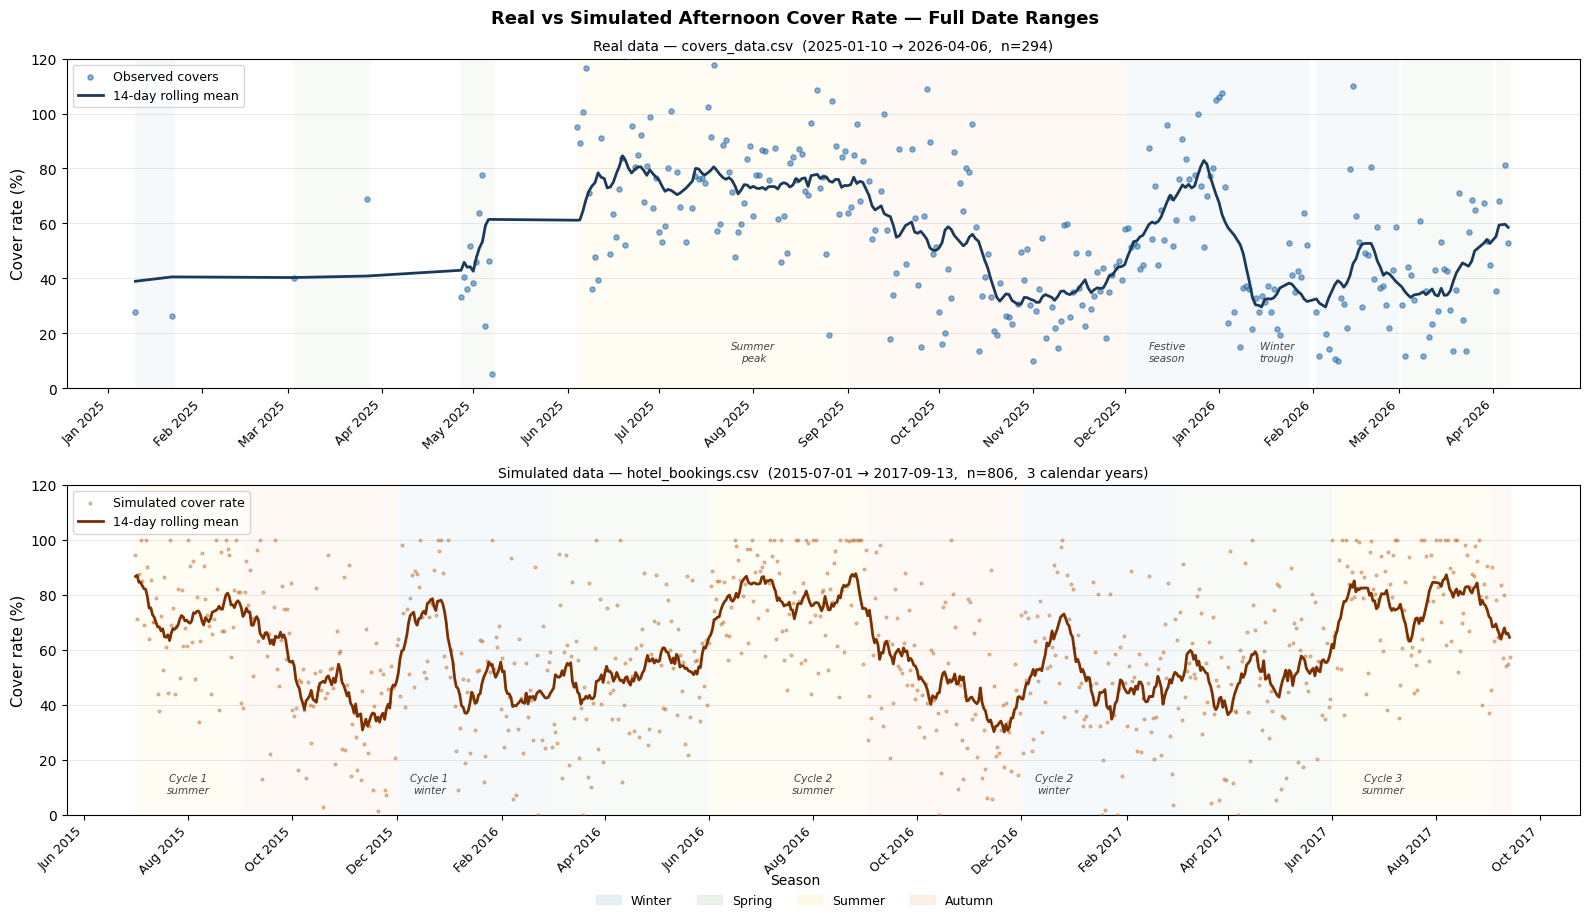

Saved → thesis/figures/real_vs_simulated_full_range.png


In [51]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates

# ── Full date ranges ────────────────────────────────────────────────────────
real_full = covers_raw[['date', 'cover_rate']].copy().sort_values('date')
real_full['cover_pct'] = real_full['cover_rate'] * 100

sim_full = daily[['date', 'dinner_cover_rate']].copy().sort_values('date')

SEASON_COLOURS = {
    'winter': '#cfe2f3', 'spring': '#d9ead3',
    'summer': '#fff2cc', 'autumn': '#fce5cd',
}

def season_of(dt):
    m = dt.month
    if m in (12, 1, 2): return 'winter'
    if m in (3, 4, 5):  return 'spring'
    if m in (6, 7, 8):  return 'summer'
    return 'autumn'

def add_season_bands(ax, dates):
    for _, grp in pd.Series(dates).groupby(pd.Series(dates).dt.to_period('M')):
        if len(grp) == 0: continue
        s = season_of(grp.iloc[0])
        ax.axvspan(grp.min(), grp.max() + pd.Timedelta(days=1),
                   alpha=0.20, color=SEASON_COLOURS[s], lw=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=False)
fig.suptitle('Real vs Simulated Afternoon Cover Rate — Full Date Ranges',
             fontsize=13, fontweight='bold')

# — Panel 1: Real data (Jan 2025 → Apr 2026) —
add_season_bands(ax1, real_full['date'])
ax1.scatter(real_full['date'], real_full['cover_pct'],
            s=14, color='#2c6fad', alpha=0.55, zorder=3, label='Observed covers')
ax1.plot(real_full['date'],
         real_full['cover_pct'].rolling(14, center=True, min_periods=5).mean(),
         color='#1a3a5c', lw=2, label='14-day rolling mean', zorder=4)
ax1.set_ylim(0, 120)
ax1.set_ylabel('Cover rate (%)', fontsize=11)
ax1.set_title(
    f'Real data — covers_data.csv  '
    f'({real_full["date"].min().date()} → {real_full["date"].max().date()},  '
    f'n={len(real_full)})',
    fontsize=10)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=9)
ax1.legend(fontsize=9, loc='upper left')
ax1.grid(axis='y', lw=0.4, alpha=0.5)

# Annotate the seasonal cycles in the real data
for label, x in [('Summer\npeak', '2025-08-01'), ('Festive\nseason', '2025-12-15'),
                  ('Winter\ntrough', '2026-01-20')]:
    ax1.annotate(label, xy=(pd.Timestamp(x), 10), fontsize=7.5,
                 color='#444', ha='center', style='italic')

# — Panel 2: Simulated data (Jul 2015 → Sep 2017) — two full seasonal cycles —
add_season_bands(ax2, sim_full['date'])
ax2.scatter(sim_full['date'], sim_full['dinner_cover_rate'],
            s=4, color='#b45309', alpha=0.35, zorder=3, label='Simulated cover rate')
ax2.plot(sim_full['date'],
         sim_full['dinner_cover_rate'].rolling(14, center=True, min_periods=5).mean(),
         color='#7c3000', lw=2, label='14-day rolling mean', zorder=4)
ax2.set_ylim(0, 120)
ax2.set_ylabel('Cover rate (%)', fontsize=11)
ax2.set_title(
    f'Simulated data — hotel_bookings.csv  '
    f'({sim_full["date"].min().date()} → {sim_full["date"].max().date()},  '
    f'n={len(sim_full)},  {len(sim_full["date"].dt.year.unique())} calendar years)',
    fontsize=10)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=9)
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(axis='y', lw=0.4, alpha=0.5)

# Mark the repeating seasonal cycles in the simulated data
for label, x in [('Cycle 1\nsummer', '2015-08-01'), ('Cycle 1\nwinter', '2015-12-20'),
                  ('Cycle 2\nsummer', '2016-08-01'), ('Cycle 2\nwinter', '2016-12-20'),
                  ('Cycle 3\nsummer', '2017-07-01')]:
    ax2.annotate(label, xy=(pd.Timestamp(x), 8), fontsize=7.5,
                 color='#444', ha='center', style='italic')

# Shared season legend
patches = [mpatches.Patch(color=c, alpha=0.5, label=s.capitalize())
           for s, c in SEASON_COLOURS.items()]
fig.legend(handles=patches, title='Season', loc='lower center',
           ncol=4, bbox_to_anchor=(0.5, -0.03), fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig('../thesis/figures/real_vs_simulated_full_range.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → thesis/figures/real_vs_simulated_full_range.png")

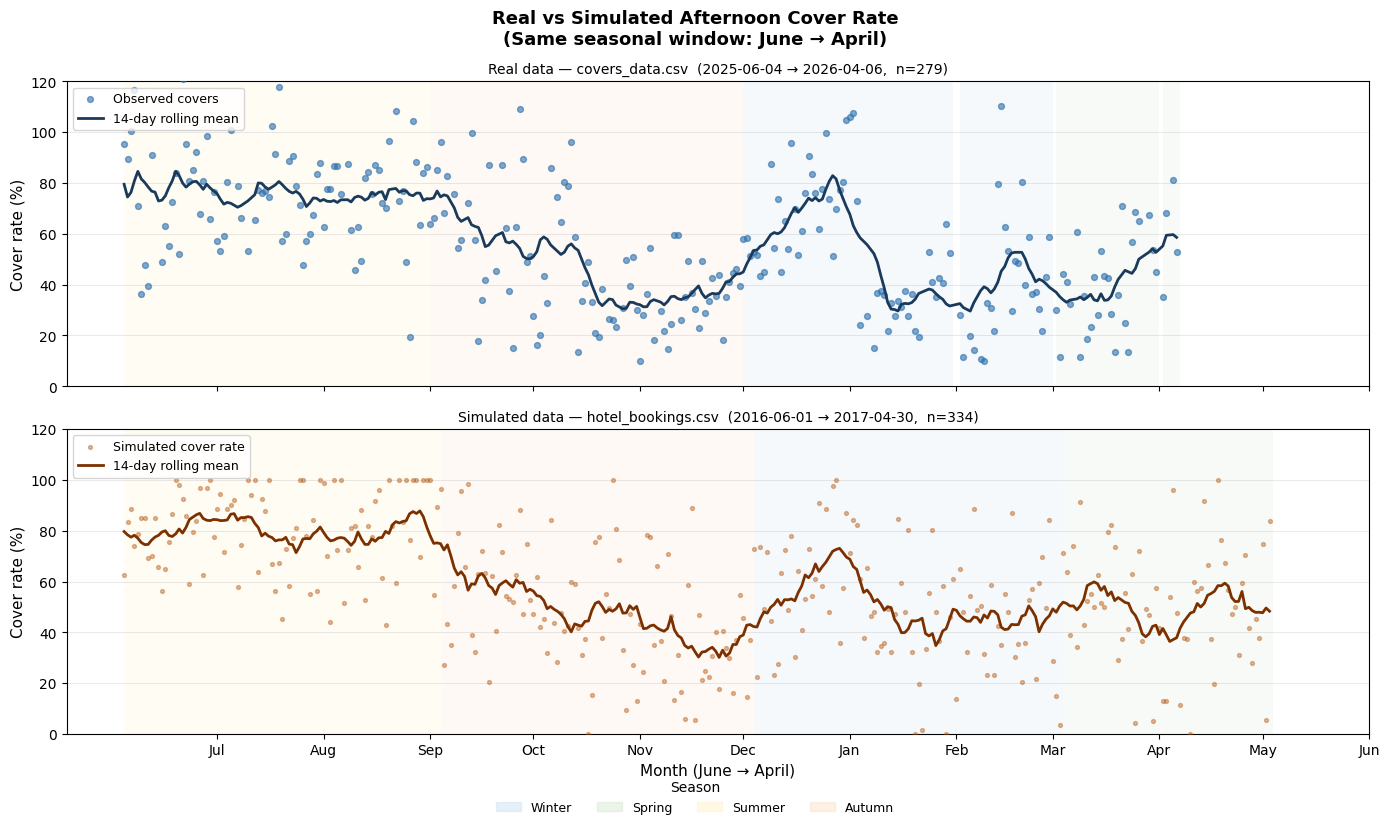

In [52]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates

# ── Filter to the same seasonal window: June → April of the following year ──
real = covers_raw[['date', 'afternoon_covers', 'cover_rate']].copy().sort_values('date')
real['cover_pct'] = real['cover_rate'] * 100
real = real[(real['date'] >= '2025-06-01') & (real['date'] <= '2026-04-30')]

sim = daily[['date', 'dinner_cover_rate']].copy().sort_values('date')
sim = sim[(sim['date'] >= '2016-06-01') & (sim['date'] <= '2017-04-30')]

# ── Season band helper ─────────────────────────────────────────────────────
SEASON_COLOURS = {
    'winter': '#cfe2f3',
    'spring': '#d9ead3',
    'summer': '#fff2cc',
    'autumn': '#fce5cd',
}

def season_of(dt):
    m = dt.month
    if m in (12, 1, 2): return 'winter'
    if m in (3, 4, 5):  return 'spring'
    if m in (6, 7, 8):  return 'summer'
    return 'autumn'

def add_season_bands(ax, dates):
    for _, grp in pd.Series(dates).groupby(pd.Series(dates).dt.to_period('M')):
        if len(grp) == 0:
            continue
        s = season_of(grp.iloc[0])
        ax.axvspan(grp.min(), grp.max() + pd.Timedelta(days=1),
                   alpha=0.20, color=SEASON_COLOURS[s], lw=0)

# ── Use relative x-axis (day offset) so both panels share the same x-scale ─
real = real.reset_index(drop=True)
sim  = sim.reset_index(drop=True)

real_start = real['date'].min()
sim_start  = sim['date'].min()

real['day'] = (real['date'] - real_start).dt.days
sim['day']  = (sim['date'] - sim_start).dt.days

# Month labels derived from the real date range (Jun → Apr)
month_labels = pd.date_range(real_start, periods=12, freq='MS')
month_ticks  = [(d - real_start).days for d in month_labels]
month_names  = [d.strftime('%b') for d in month_labels]

# ── Plot ───────────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle('Real vs Simulated Afternoon Cover Rate\n(Same seasonal window: June → April)',
             fontsize=13, fontweight='bold')

# Season bands keyed by day offset for each panel
for ax, df in [(ax1, real), (ax2, sim)]:
    for _, grp in df.groupby(df['date'].dt.to_period('M')):
        if grp.empty:
            continue
        s = season_of(grp['date'].iloc[0])
        ax.axvspan(grp['day'].min(), grp['day'].max() + 1,
                   alpha=0.20, color=SEASON_COLOURS[s], lw=0)

# — Panel 1: Real data —
ax1.scatter(real['day'], real['cover_pct'],
            s=18, color='#2c6fad', alpha=0.60, zorder=3, label='Observed covers')
ax1.plot(real['day'],
         real['cover_pct'].rolling(14, center=True, min_periods=5).mean(),
         color='#1a3a5c', lw=2, label='14-day rolling mean', zorder=4)
ax1.set_ylim(0, 120)
ax1.set_ylabel('Cover rate (%)', fontsize=11)
ax1.set_title(
    f'Real data — covers_data.csv  '
    f'({real["date"].min().date()} → {real["date"].max().date()},  n={len(real)})',
    fontsize=10)
ax1.legend(fontsize=9, loc='upper left')
ax1.grid(axis='y', lw=0.4, alpha=0.5)

# — Panel 2: Simulated data —
ax2.scatter(sim['day'], sim['dinner_cover_rate'],
            s=8, color='#b45309', alpha=0.40, zorder=3, label='Simulated cover rate')
ax2.plot(sim['day'],
         sim['dinner_cover_rate'].rolling(14, center=True, min_periods=5).mean(),
         color='#7c3000', lw=2, label='14-day rolling mean', zorder=4)
ax2.set_ylim(0, 120)
ax2.set_ylabel('Cover rate (%)', fontsize=11)
ax2.set_title(
    f'Simulated data — hotel_bookings.csv  '
    f'({sim["date"].min().date()} → {sim["date"].max().date()},  n={len(sim)})',
    fontsize=10)
ax2.legend(fontsize=9, loc='upper left')
ax2.grid(axis='y', lw=0.4, alpha=0.5)

# Shared x-axis: month labels
ax2.set_xticks(month_ticks)
ax2.set_xticklabels(month_names, fontsize=10)
ax2.set_xlabel('Month (June → April)', fontsize=11)

# Season legend
patches = [mpatches.Patch(color=c, alpha=0.5, label=s.capitalize())
           for s, c in SEASON_COLOURS.items()]
fig.legend(handles=patches, title='Season', loc='lower center',
           ncol=4, bbox_to_anchor=(0.5, -0.04), fontsize=9, frameon=False)

plt.tight_layout()
plt.savefig('../thesis/figures/real_vs_simulated_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()